# OTC Medicine Information Organization System

## Automatic Classification of Documented Safety Risks

### Objective

Develop and evaluate a supervised multi-label
classification model that assigns documented
safety risk categories to OTC medicines based
on their selected warning texts.

### Methodology

- TF-IDF text representation
- Multi-label logistic regression
- Training and held-out testing
- Precision, recall, and F1-score
- Classification error analysis
- Prediction of the remaining 100 medicines

### Research Question

How effectively can a supervised machine learning
model reproduce the developed Documented Safety
Risk taxonomy using unstructured medication
warning texts?

### Data Limitation

The reference labels were generated with AI
assistance and subsequently human-verified.
Rare and unrepresented categories may limit
model performance.

In [1]:
# Import essential libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load datasets

labeled = pd.read_csv("/content/OTC_Labeled_200.csv")

unlabeled = pd.read_csv("/content/OTC_Unlabeled_100.csv")

risk_distribution = pd.read_csv(
    "/content/OTC_Risk_Category_Distribution.csv"
)

# Inspect datasets

print("Labeled dataset:", labeled.shape)
print("Unlabeled dataset:", unlabeled.shape)
print("Risk distribution:", risk_distribution.shape)

print("\nLabeled dataset columns:")
print(labeled.columns.tolist())

display(labeled.head(3))

Labeled dataset: (200, 15)
Unlabeled dataset: (100, 15)
Risk distribution: (9, 3)

Labeled dataset columns:
['Item', 'Groups', 'Product', 'Selected Warnings', 'R01_Organ_Toxicity', 'R02_Bleeding', 'R03_Cardiovascular', 'R04_Allergic_Reactions', 'R05_Neurological_Behavioral', 'R06_Skin_Local_Tissue', 'R07_Gastrointestinal', 'R08_Other_Documented_Risk', 'R09_Risk_Not_Specified', 'Evidence', 'Coding_Notes']


,Item,Groups,Product,Selected Warnings,R01_Organ_Toxicity,R02_Bleeding,R03_Cardiovascular,R04_Allergic_Reactions,R05_Neurological_Behavioral,R06_Skin_Local_Tissue,R07_Gastrointestinal,R08_Other_Documented_Risk,R09_Risk_Not_Specified,Evidence,Coding_Notes
0,2,Pain and Fever,Advil,NSAID may cause severe stomach bleeding; may i...,0,1,1,0,0,0,0,0,0,NSAID may cause severe stomach bleeding; may i...,Explicit outcome(s) in excerpt; no additional ...
1,4,Pain and Fever,Bayer Genuine Aspirin,Children/teens recovering from chickenpox or f...,0,1,0,0,0,0,0,1,0,Children/teens recovering from chickenpox or f...,Explicit outcome(s) in excerpt; no additional ...
2,5,Pain and Fever,Children's Tylenol,Severe liver damage possible if child exceeds ...,1,0,0,0,0,1,0,0,0,Severe liver damage possible if child exceeds ...,Explicit outcome(s) in excerpt; no additional ...


## Preparation of Features and Target Labels

The Selected Warnings column is used as the
input feature (X), while the nine binary risk
categories serve as target labels (Y).

This is a multi-label classification problem
because a medicine may belong to multiple
risk categories simultaneously.

Product names, therapeutic groups, evidence,
and coding notes are excluded from the model
inputs to reduce the risk of data leakage.

The model is intended to classify documented
risks rather than infer clinical safety.

In [2]:
# Identify the nine risk categories

risk_columns = [
    col for col in labeled.columns
    if col.startswith(tuple(
        f"R{i:02d}_" for i in range(1, 10)
    ))
]

# Define input features

X = labeled["Selected Warnings"].fillna("").astype(str)

# Define target labels

Y = labeled[risk_columns].astype(int)

# Prepare the unlabeled warning texts

X_unlabeled = (
    unlabeled["Selected Warnings"]
    .fillna("")
    .astype(str)
)

# Inspect model inputs and outputs

print("Input dimensions (X):", X.shape)
print("Target dimensions (Y):", Y.shape)
print("Unlabeled inputs:", X_unlabeled.shape)

print("\nNumber of risk categories:", len(risk_columns))

print("\nEmpty warning texts:",
      X.str.strip().eq("").sum())

print("Duplicate warning texts:",
      X.duplicated().sum())

print("\nPositive examples per category:")
print(Y.sum())

print("\nExample input:")
print(X.iloc[0])

print("\nCorresponding target labels:")
print(Y.iloc[0])

Input dimensions (X): (200,)
Target dimensions (Y): (200, 9)
Unlabeled inputs: (100,)

Number of risk categories: 9

Empty warning texts: 0
Duplicate warning texts: 25

Positive examples per category:
R01_Organ_Toxicity              20
R02_Bleeding                    28
R03_Cardiovascular              16
R04_Allergic_Reactions           3
R05_Neurological_Behavioral     39
R06_Skin_Local_Tissue           19
R07_Gastrointestinal             0
R08_Other_Documented_Risk       20
R09_Risk_Not_Specified         101
dtype: int64

Example input:
NSAID may cause severe stomach bleeding; may increase risk of 
heart attack, heart failure or stroke

Corresponding target labels:
R01_Organ_Toxicity             0
R02_Bleeding                   1
R03_Cardiovascular             1
R04_Allergic_Reactions         0
R05_Neurological_Behavioral    0
R06_Skin_Local_Tissue          0
R07_Gastrointestinal           0
R08_Other_Documented_Risk      0
R09_Risk_Not_Specified         0
Name: 0, dtype: int64


## Investigation of Duplicate Warning Texts

The labeled dataset contains 25 repeated warning
texts beyond their first occurrences.

Identical warning texts may occur across distinct
products, brands, or dosage formulations.

Removing these records would reduce the coverage
of the information organization system.

Instead, duplicate warning texts are investigated
for classification consistency and grouped
during training and testing to reduce data leakage.

In [3]:
# Normalize warning texts for duplicate detection

normalized_warnings = (
    X.str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Identify all records with duplicate warnings

duplicate_records = labeled.loc[
    normalized_warnings.duplicated(keep=False)
].copy()

duplicate_records["Warning_Group"] = (
    normalized_warnings.loc[duplicate_records.index]
)

# Sort identical warnings together

duplicate_records = duplicate_records.sort_values(
    "Warning_Group"
)

print("Total medicines:", len(labeled))

print("Unique normalized warning texts:",
      normalized_warnings.nunique())

print("Medicines involved in duplicate groups:",
      len(duplicate_records))

print("Number of duplicate warning groups:",
      duplicate_records["Warning_Group"].nunique())

# Display examples

display(
    duplicate_records[
        ["Item", "Product", "Selected Warnings"]
    ].head(15)
)

Total medicines: 200
Unique normalized warning texts: 173
Medicines involved in duplicate groups: 47
Number of duplicate warning groups: 20


,Item,Product,Selected Warnings
85,129,Equate Allergy Relief,Ask a doctor with liver/kidney disease; taking...
84,127,CVS Allergy Relief,Ask a doctor with liver/kidney disease; taking...
69,108,Mucinex DM Maximum Strength,Avoid MAOIs; consult clinician for persistent ...
62,97,Vicks DayQuil Cough,Avoid MAOIs; consult clinician for persistent ...
128,194,Maalox Maximum Strength,Consult a doctor before use if you have kidney...
127,193,Mylanta Maximum Strength,Consult a doctor before use if you have kidney...
54,84,Mucinex Sinus-Max Severe Congestion & Pain,Do not combine with other medicines containing...
50,80,Alka-Seltzer Plus Cold & Flu,Do not combine with other medicines containing...
134,200,Gas-X Extra Strength,Do not exceed labeled doses; consult a doctor ...
135,201,Phazyme Maximum Strength,Do not exceed labeled doses; consult a doctor ...


In [4]:
# Check whether identical warnings have
# inconsistent risk classifications

consistency_check = (
    duplicate_records
    .groupby("Warning_Group")[risk_columns]
    .nunique()
)

inconsistent_groups = consistency_check[
    (consistency_check > 1).any(axis=1)
]

print("Duplicate groups with inconsistent labels:",
      len(inconsistent_groups))

if len(inconsistent_groups) > 0:

    display(
        duplicate_records[
            duplicate_records["Warning_Group"].isin(
                inconsistent_groups.index
            )
        ][
            ["Item", "Product", "Selected Warnings"]
            + risk_columns
        ]
    )

else:
    print("All identical warning texts have consistent labels.")

Duplicate groups with inconsistent labels: 0
All identical warning texts have consistent labels.


## Training and Testing Dataset Split

A group-based 80:20 training and testing split
is performed using GroupShuffleSplit.

Medicines with identical normalized warning
texts are assigned to the same partition to
prevent exact duplicate text leakage.

A fixed random seed of 42 ensures reproducibility.

The distribution of risk categories is examined
across both partitions, particularly for rare
and unrepresented categories.

In [5]:
from sklearn.model_selection import GroupShuffleSplit

# Define the group-based splitting method

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

# Generate training and testing indices

train_idx, test_idx = next(
    splitter.split(X, Y, groups=normalized_warnings)
)

# Create training and testing datasets

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

Y_train = Y.iloc[train_idx]
Y_test = Y.iloc[test_idx]

# Verify dataset sizes

print("Training medicines:", len(X_train))
print("Testing medicines:", len(X_test))

print("\nTraining percentage:",
      round(len(X_train) / len(X) * 100, 2))

print("Testing percentage:",
      round(len(X_test) / len(X) * 100, 2))

# Check for duplicate warning leakage

train_warnings = set(normalized_warnings.iloc[train_idx])
test_warnings = set(normalized_warnings.iloc[test_idx])

overlap = train_warnings.intersection(test_warnings)

print("\nOverlapping warning texts:", len(overlap))

Training medicines: 164
Testing medicines: 36

Training percentage: 82.0
Testing percentage: 18.0

Overlapping warning texts: 0


In [6]:
# Compare category frequencies across partitions

split_distribution = pd.DataFrame({
    "Total": Y.sum(),
    "Training": Y_train.sum(),
    "Testing": Y_test.sum()
})

display(split_distribution)

# Identify categories without training examples

print("\nCategories without training examples:")

print(
    split_distribution[
        split_distribution["Training"] == 0
    ].index.tolist()
)

# Identify categories without testing examples

print("\nCategories without testing examples:")

print(
    split_distribution[
        split_distribution["Testing"] == 0
    ].index.tolist()
)

,Total,Training,Testing
R01_Organ_Toxicity,20,16,4
R02_Bleeding,28,22,6
R03_Cardiovascular,16,12,4
R04_Allergic_Reactions,3,2,1
R05_Neurological_Behavioral,39,33,6
R06_Skin_Local_Tissue,19,17,2
R07_Gastrointestinal,0,0,0
R08_Other_Documented_Risk,20,15,5
R09_Risk_Not_Specified,101,85,16



Categories without training examples:
['R07_Gastrointestinal']

Categories without testing examples:
['R07_Gastrointestinal']


## TF-IDF Feature Extraction

Warning texts are transformed into numerical
feature vectors using Term Frequency-Inverse
Document Frequency (TF-IDF).

Both unigrams (individual words) and bigrams
(two-word phrases) are included to capture
meaningful expressions such as "stomach bleeding",
"liver damage", and "heart attack".

The vectorizer is fitted exclusively on the
training dataset to prevent information leakage
from the testing dataset.

The same fitted vectorizer is subsequently used
to transform the testing and unlabeled datasets.

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize the TF-IDF vectorizer

tfidf = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=1,
    max_features=5000,
    sublinear_tf=True
)

# Learn vocabulary from training data only

X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing data

X_test_tfidf = tfidf.transform(X_test)

# Transform the remaining 100 medicines

X_unlabeled_tfidf = tfidf.transform(X_unlabeled)

# Inspect the resulting feature matrices

print("Training TF-IDF matrix:",
      X_train_tfidf.shape)

print("Testing TF-IDF matrix:",
      X_test_tfidf.shape)

print("Unlabeled TF-IDF matrix:",
      X_unlabeled_tfidf.shape)

print("\nVocabulary size:",
      len(tfidf.get_feature_names_out()))

print("\nExample vocabulary terms:")

print(tfidf.get_feature_names_out()[:30])

Training TF-IDF matrix: (164, 1299)
Testing TF-IDF matrix: (36, 1299)
Unlabeled TF-IDF matrix: (100, 1299)

Vocabulary size: 1299

Example vocabulary terms:
['14' '14 day' '14 days' 'abdominal' 'abdominal pain' 'absorption'
 'absorption of' 'acetaminophen' 'acetaminophen and' 'acetaminophen can'
 'acetaminophen containing' 'acetaminophen drugs' 'acetaminophen liver'
 'acetaminophen may' 'acetaminophen or' 'acetaminophen overdose'
 'acetaminophen products' 'acid' 'acid reducers' 'active'
 'active ingredients' 'actives' 'actives avoid' 'actives before'
 'adequate' 'adequate fluid' 'advice' 'advice and' 'advice consult'
 'advice for']


In [8]:
# Inspect the first training warning

feature_names = tfidf.get_feature_names_out()

first_vector = X_train_tfidf[0].toarray().flatten()

top_indices = first_vector.argsort()[::-1][:10]

top_terms = pd.DataFrame({
    "Term": feature_names[top_indices],
    "TF_IDF_Score": first_vector[top_indices]
})

print("Original warning:")
print(X_train.iloc[0])

print("\nTop TF-IDF terms:")

display(
    top_terms[top_terms["TF_IDF_Score"] > 0]
)

Original warning:
Children/teens recovering from chickenpox or flu-like illness should not use 
because of Reye's syndrome risk; may cause severe stomach bleeding.

Top TF-IDF terms:


,Term,TF_IDF_Score
0,risk may,0.195097
1,illness should,0.195097
2,children teens,0.180482
3,recovering from,0.180482
4,recovering,0.180482
5,or flu,0.180482
6,should not,0.180482
7,teens recovering,0.180482
8,from chickenpox,0.180482
9,like illness,0.180482


## Multi-label Logistic Regression Model

A One-vs-Rest logistic regression model is
trained to predict multiple documented safety
risk categories from TF-IDF warning features.

Each learnable specific risk category is
treated as an independent binary
classification problem.

Balanced class weights are applied to address
the unequal distribution of risk categories.

R07 (Gastrointestinal) is excluded from model
training because no positive examples are
available.

R09 (Risk Not Specified) is derived from the
absence of predicted specific risk categories
rather than trained as an independent classifier.

This preserves the exclusivity of the residual
category within the classification scheme.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

# Identify learnable specific risk categories

trainable_columns = [
    col for col in risk_columns
    if not col.startswith("R09_")
    and Y_train[col].nunique() == 2
]

print("Trainable risk categories:")

for col in trainable_columns:
    print(col)

# Initialize the multi-label classification model

model = OneVsRestClassifier(
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42,
        C=1.0
    )
)

# Train the model

model.fit(
    X_train_tfidf,
    Y_train[trainable_columns]
)

print("\nModel training completed successfully!")

print("Number of trained classifiers:",
      len(model.estimators_))

Trainable risk categories:
R01_Organ_Toxicity
R02_Bleeding
R03_Cardiovascular
R04_Allergic_Reactions
R05_Neurological_Behavioral
R06_Skin_Local_Tissue
R08_Other_Documented_Risk

Model training completed successfully!
Number of trained classifiers: 7


## Prediction on the Held-Out Testing Dataset

The trained multi-label logistic regression
model is applied to the held-out testing dataset.

Predictions are reconstructed into the original
nine-category taxonomy.

R07 is assigned a constant value of zero because
no positive training examples were available.

R09 is assigned when no specific risk category
is predicted, preserving its exclusivity.

The predicted labels are compared with the
human-verified reference classifications to
evaluate model performance.

In [10]:
# Generate predictions for the seven trained categories

raw_predictions = model.predict(X_test_tfidf)

# Create a dataframe containing all nine risk categories

Y_pred = pd.DataFrame(
    0,
    index=Y_test.index,
    columns=risk_columns
)

# Insert predictions for the trained categories

Y_pred[trainable_columns] = raw_predictions

# Derive R09 from the absence of specific risk predictions

specific_risk_columns = [
    col for col in risk_columns
    if not col.startswith("R09_")
]

Y_pred["R09_Risk_Not_Specified"] = (
    Y_pred[specific_risk_columns].sum(axis=1) == 0
).astype(int)

# Inspect prediction results

print("Prediction dimensions:", Y_pred.shape)

print("\nPredicted category frequencies:")
print(Y_pred.sum())

print("\nActual category frequencies:")
print(Y_test.sum())

display(Y_pred.head())

Prediction dimensions: (36, 9)

Predicted category frequencies:
R01_Organ_Toxicity              4
R02_Bleeding                    7
R03_Cardiovascular              3
R04_Allergic_Reactions          1
R05_Neurological_Behavioral     8
R06_Skin_Local_Tissue           1
R07_Gastrointestinal            0
R08_Other_Documented_Risk       4
R09_Risk_Not_Specified         17
dtype: int64

Actual category frequencies:
R01_Organ_Toxicity              4
R02_Bleeding                    6
R03_Cardiovascular              4
R04_Allergic_Reactions          1
R05_Neurological_Behavioral     6
R06_Skin_Local_Tissue           2
R07_Gastrointestinal            0
R08_Other_Documented_Risk       5
R09_Risk_Not_Specified         16
dtype: int64


,R01_Organ_Toxicity,R02_Bleeding,R03_Cardiovascular,R04_Allergic_Reactions,R05_Neurological_Behavioral,R06_Skin_Local_Tissue,R07_Gastrointestinal,R08_Other_Documented_Risk,R09_Risk_Not_Specified
0,0,1,1,0,0,0,0,0,0
3,0,1,1,0,0,0,0,0,0
5,1,0,0,0,0,1,0,0,0
7,1,1,0,0,1,0,0,0,0
21,1,1,0,0,1,0,0,0,0


,Actual,Predicted,Difference
R01_Organ_Toxicity,4,4,0
R02_Bleeding,6,7,1
R03_Cardiovascular,4,3,-1
R04_Allergic_Reactions,1,1,0
R05_Neurological_Behavioral,6,8,2
R06_Skin_Local_Tissue,2,1,-1
R07_Gastrointestinal,0,0,0
R08_Other_Documented_Risk,5,4,-1
R09_Risk_Not_Specified,16,17,1


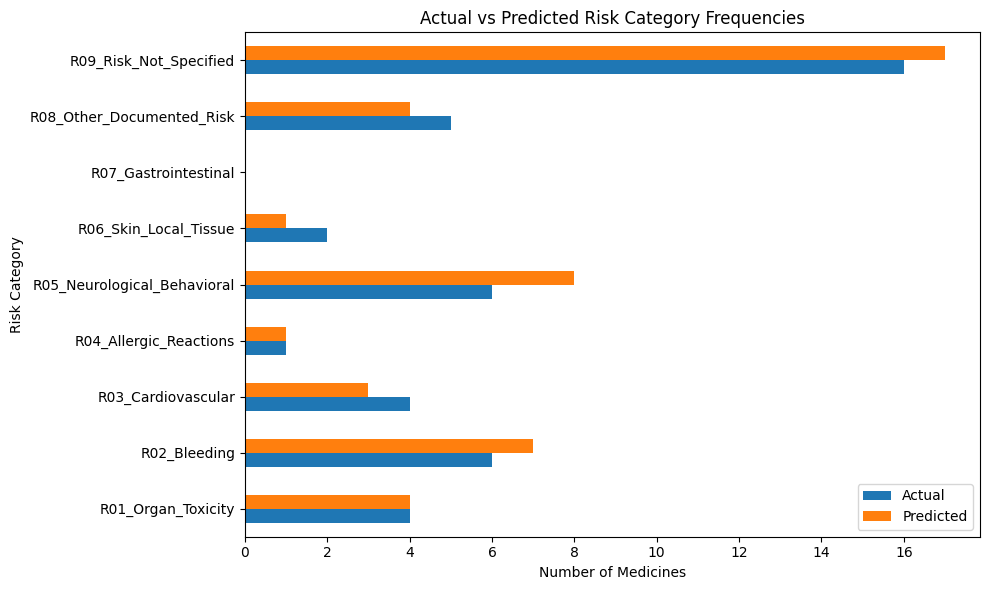

In [11]:
# Compare actual and predicted category frequencies

prediction_comparison = pd.DataFrame({
    "Actual": Y_test.sum(),
    "Predicted": Y_pred.sum()
})

prediction_comparison["Difference"] = (
    prediction_comparison["Predicted"] -
    prediction_comparison["Actual"]
)

display(prediction_comparison)

# Visualize actual versus predicted frequencies

prediction_comparison[["Actual", "Predicted"]].plot(
    kind="barh",
    figsize=(10, 6),
    title="Actual vs Predicted Risk Category Frequencies"
)

plt.xlabel("Number of Medicines")
plt.ylabel("Risk Category")
plt.tight_layout()
plt.show()

## Evaluation of Classification Performance

Model performance is evaluated using micro-averaged
precision, recall, and F1-score, exact match
accuracy, and Hamming loss.

Micro-averaged metrics aggregate classification
decisions across all risk categories.

Macro F1-score is also calculated for the eight
categories represented in the reference dataset
to examine performance across both common and
rare categories.

R07 is excluded from macro F1 because it has
no positive reference examples.

In [12]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    hamming_loss
)

# Identify categories with positive reference examples

evaluated_columns = [
    col for col in risk_columns
    if Y_test[col].sum() > 0
]

# Calculate evaluation metrics

metrics = {
    "Micro Precision": precision_score(
        Y_test, Y_pred, average="micro", zero_division=0
    ),

    "Micro Recall": recall_score(
        Y_test, Y_pred, average="micro", zero_division=0
    ),

    "Micro F1-score": f1_score(
        Y_test, Y_pred, average="micro", zero_division=0
    ),

    "Macro F1-score (Supported Categories)": f1_score(
        Y_test[evaluated_columns],
        Y_pred[evaluated_columns],
        average="macro",
        zero_division=0
    ),

    "Exact Match Accuracy": accuracy_score(
        Y_test, Y_pred
    ),

    "Hamming Loss": hamming_loss(
        Y_test, Y_pred
    )
}

# Display evaluation results

evaluation_results = pd.DataFrame(
    metrics.items(),
    columns=["Metric", "Score"]
)

display(evaluation_results.round(4))

,Metric,Score
0,Micro Precision,0.8889
1,Micro Recall,0.9091
2,Micro F1-score,0.8989
3,Macro F1-score (Supported Categories),0.8675
4,Exact Match Accuracy,0.8333
5,Hamming Loss,0.0278


## Baseline Model Comparison

A majority-label baseline is established to
assess whether the supervised classification
model provides meaningful improvements over
a simple classification strategy.

The baseline assigns every testing medicine
to R09 (Risk Not Specified), the most frequent
category in the training dataset.

Both models are evaluated using the same
held-out testing dataset and evaluation metrics.

In [13]:
# Create majority-label baseline predictions

Y_baseline = pd.DataFrame(
    0,
    index=Y_test.index,
    columns=risk_columns
)

# Assign every medicine to R09

Y_baseline["R09_Risk_Not_Specified"] = 1

# Evaluate baseline performance

baseline_metrics = {
    "Micro Precision": precision_score(
        Y_test, Y_baseline,
        average="micro", zero_division=0
    ),

    "Micro Recall": recall_score(
        Y_test, Y_baseline,
        average="micro", zero_division=0
    ),

    "Micro F1-score": f1_score(
        Y_test, Y_baseline,
        average="micro", zero_division=0
    ),

    "Macro F1-score (Supported Categories)": f1_score(
        Y_test[evaluated_columns],
        Y_baseline[evaluated_columns],
        average="macro", zero_division=0
    ),

    "Exact Match Accuracy": accuracy_score(
        Y_test, Y_baseline
    ),

    "Hamming Loss": hamming_loss(
        Y_test, Y_baseline
    )
}

# Compare baseline and machine learning model

model_comparison = pd.DataFrame({
    "Baseline": baseline_metrics,
    "Logistic Regression": metrics
})

display(model_comparison.round(4))

,Baseline,Logistic Regression
Micro Precision,0.4444,0.8889
Micro Recall,0.3636,0.9091
Micro F1-score,0.4000,0.8989
Macro F1-score (Supported Categories),0.0769,0.8675
Exact Match Accuracy,0.4444,0.8333
Hamming Loss,0.1481,0.0278


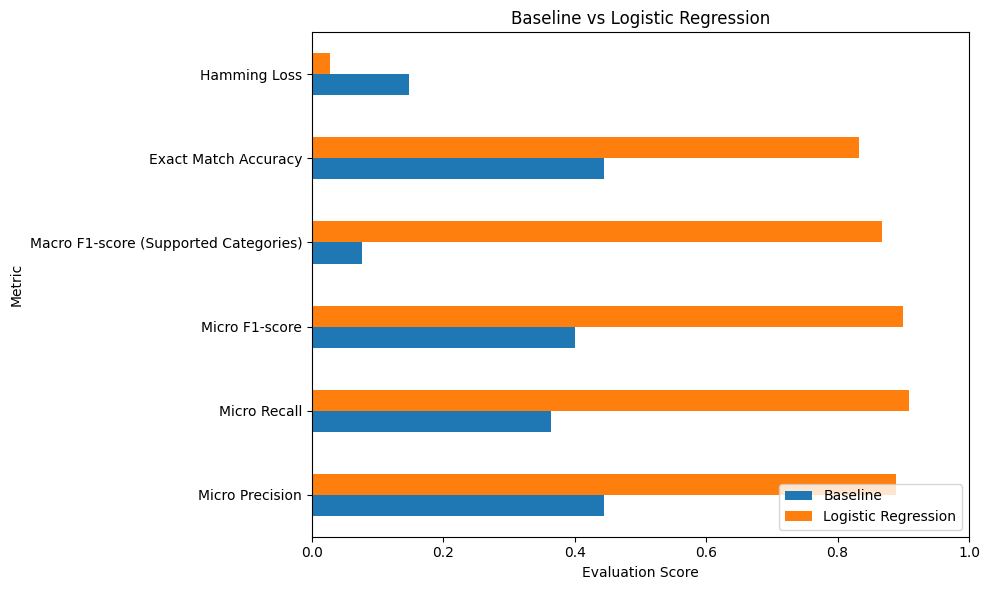

In [14]:
# Compare the two models visually

model_comparison.plot(
    kind="barh",
    figsize=(10, 6),
    title="Baseline vs Logistic Regression"
)

plt.xlabel("Evaluation Score")
plt.ylabel("Metric")
plt.xlim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Category-Level Performance Evaluation

Individual risk categories are evaluated using
precision, recall, F1-score, and support.

This analysis examines whether the overall
performance conceals weaknesses in rare or
underrepresented categories.

True positives, false positives, and false
negatives are examined to identify systematic
classification errors.

Categories without positive reference examples
are identified as unsupported rather than
interpreted as successfully classified.

In [15]:
from sklearn.metrics import (
    precision_recall_fscore_support,
    multilabel_confusion_matrix
)

# Calculate category-level metrics

precision, recall, f1, support = (
    precision_recall_fscore_support(
        Y_test,
        Y_pred,
        average=None,
        zero_division=0
    )
)

# Calculate confusion matrices

matrices = multilabel_confusion_matrix(
    Y_test, Y_pred
)

# Create category-level evaluation table

category_results = pd.DataFrame({
    "Risk_Category": risk_columns,
    "Precision": precision,
    "Recall": recall,
    "F1_Score": f1,
    "Support": support,
    "True_Positives": matrices[:, 1, 1],
    "False_Positives": matrices[:, 0, 1],
    "False_Negatives": matrices[:, 1, 0]
})

# Mark unsupported categories

category_results.loc[
    category_results["Support"] == 0,
    ["Precision", "Recall", "F1_Score"]
] = np.nan

display(category_results.round(4))

,Risk_Category,Precision,Recall,F1_Score,Support,True_Positives,False_Positives,False_Negatives
0,R01_Organ_Toxicity,1.0000,1.00,1.0000,4,4,0,0
1,R02_Bleeding,0.8571,1.00,0.9231,6,6,1,0
2,R03_Cardiovascular,1.0000,0.75,0.8571,4,3,0,1
3,R04_Allergic_Reactions,1.0000,1.00,1.0000,1,1,0,0
4,R05_Neurological_Behavioral,0.7500,1.00,0.8571,6,6,2,0
5,R06_Skin_Local_Tissue,1.0000,0.50,0.6667,2,1,0,1
6,R07_Gastrointestinal,NaN,NaN,NaN,0,0,0,0
7,R08_Other_Documented_Risk,0.7500,0.60,0.6667,5,3,1,2
8,R09_Risk_Not_Specified,0.9412,1.00,0.9697,16,16,1,0


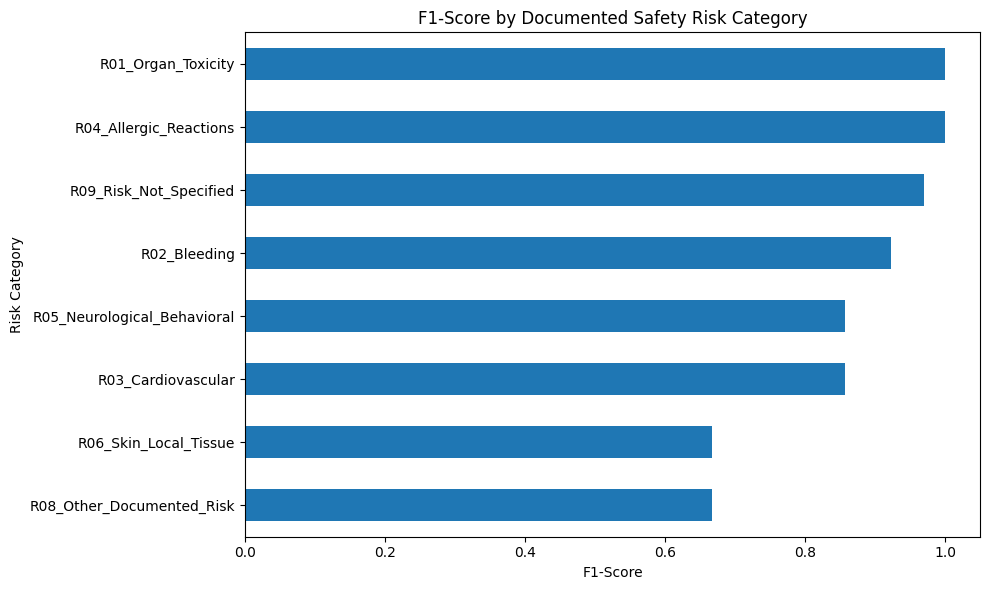

In [16]:
# Plot F1-scores for supported categories

supported_results = category_results[
    category_results["Support"] > 0
]

supported_results.set_index(
    "Risk_Category"
)["F1_Score"].sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="F1-Score by Documented Safety Risk Category"
)

plt.xlabel("F1-Score")
plt.ylabel("Risk Category")
plt.xlim(0, 1.05)
plt.tight_layout()
plt.show()

## Classification Error Analysis

Misclassified medicines are examined to identify
differences between the reference taxonomy and
machine-generated classifications.

False positives and false negatives are analyzed
at the individual medicine level.

The analysis investigates whether classification
errors arise from:

- Limited training examples
- Ambiguous category boundaries
- Heterogeneous residual categories
- Limitations of text representation
- Differences in interpretation of warning text

This analysis helps identify limitations in both
the classification model and the taxonomy itself.

In [17]:
# Identify incorrectly classified medicines

error_mask = (Y_test != Y_pred).any(axis=1)

# Extract misclassified records

error_analysis = labeled.loc[
    Y_test.index[error_mask],
    ["Item", "Groups", "Product", "Selected Warnings"]
].copy()

# Convert binary labels into readable risk codes

def get_risk_codes(row):
    return "; ".join([
        col.split("_")[0]
        for col in risk_columns
        if row[col] == 1
    ])

# Record actual and predicted risk codes

error_analysis["Actual_Risks"] = (
    Y_test.loc[error_analysis.index]
    .apply(get_risk_codes, axis=1)
)

error_analysis["Predicted_Risks"] = (
    Y_pred.loc[error_analysis.index]
    .apply(get_risk_codes, axis=1)
)

# Identify missed risks (false negatives)

error_analysis["Missed_Risks"] = (
    (Y_test == 1) & (Y_pred == 0)
).loc[error_analysis.index].apply(
    get_risk_codes, axis=1
)

# Identify extra predicted risks (false positives)

error_analysis["Extra_Risks"] = (
    (Y_test == 0) & (Y_pred == 1)
).loc[error_analysis.index].apply(
    get_risk_codes, axis=1
)

# Display results

print("Total testing medicines:", len(Y_test))

print("Correctly classified medicines:",
      (~error_mask).sum())

print("Misclassified medicines:",
      error_mask.sum())

pd.set_option("display.max_colwidth", None)

display(error_analysis)

Total testing medicines: 36
Correctly classified medicines: 30
Misclassified medicines: 6


,Item,Groups,Product,Selected Warnings,Actual_Risks,Predicted_Risks,Missed_Risks,Extra_Risks
7,15,Pain and Fever,Advil Dual Action with Acetaminophen,Ibuprofen may cause severe stomach bleeding or cardiovascular events; excessive acetaminophen may cause severe liver damage.,R01; R02; R03,R01; R02; R05,R03,R05
21,35,Pain and Fever,Excedrin Tension Headache,Excess acetaminophen may cause liver damage; caffeine may cause nervousness.,R01; R05,R01; R02; R05,,R02
28,45,Pain and Fever,ThermaCare HeatWraps Back Pain Therapy,May cause burns; avoid sleeping with wrap and follow age restrictions.,R06,R05,R06,R05
64,99,Cough Cold & Flu,Vicks Sinex Severe Nasal Spray,Do not exceed labeled duration; prolonged use may worsen congestion.,R08,R09,R08,R09
106,161,Allergy & Respiratory,Astepro Children's Allergy Nasal Spray,May cause drowsiness or bitter taste; follow age restrictions.,R05; R08,R05,R08,
144,219,Digestive & Heartburn,Imodium Multi-Symptom Relief,Excess loperamide can cause serious heart problems; avoid use with bloody stool.,R03,R03; R08,,R08


## Interpretation of Learned Classification Features

The coefficients of the trained logistic
regression classifiers are examined to identify
words and phrases associated with each risk
category.

This analysis compares machine-learned textual
patterns with the classificatory principles
defined in the manually constructed taxonomy.

It also investigates whether the model learns
meaningful risk-related terminology or relies
on incidental statistical associations.

In [18]:
# Extract the vocabulary

feature_names = tfidf.get_feature_names_out()

# Identify the most influential positive features
# for each trained risk category

feature_analysis = []

for category, estimator in zip(
    trainable_columns, model.estimators_
):

    coefficients = estimator.coef_[0]

    top_indices = np.argsort(coefficients)[::-1][:10]

    for rank, idx in enumerate(top_indices, start=1):

        feature_analysis.append({
            "Risk_Category": category,
            "Rank": rank,
            "Feature": feature_names[idx],
            "Coefficient": coefficients[idx]
        })

# Convert results into a dataframe

feature_analysis = pd.DataFrame(feature_analysis)

# Display the top 10 features for each category

feature_table = feature_analysis.pivot(
    index="Rank",
    columns="Risk_Category",
    values="Feature"
)

display(feature_table)

Risk_Category,R01_Organ_Toxicity,R02_Bleeding,R03_Cardiovascular,R04_Allergic_Reactions,R05_Neurological_Behavioral,R06_Skin_Local_Tissue,R08_Other_Documented_Risk
Rank,,,,,,,
1,acetaminophen,bleeding,heart,allergic,drowsiness,irritation,choking
2,damage,stomach bleeding,may increase,appropriate,may cause,if,exceed recommended
3,liver,stomach,blood pressure,use age,cause,if irritation,recommended
4,liver damage,cause stomach,pressure,age appropriate,may,develops,reye syndrome
5,severe liver,may cause,pressure or,severe allergic,cause drowsiness,irritation develops,syndrome
6,severe,nsaid,increase,appropriate dosing,marked drowsiness,stop,reye
7,acetaminophen may,may,blood,allergic reactions,marked,stop use,risk
8,excessive,cause,pseudoephedrine,or severe,nervousness,nasal,choking risk
9,cause severe,aspirin,pseudoephedrine may,bleeding or,cause nervousness,nosebleeds,water


## Automatic Classification of the Remaining Medicines

Following held-out evaluation and error analysis,
the TF-IDF vectorizer and multi-label logistic
regression model are refitted using all 200
labeled medicines.

The final model is applied to the remaining
100 unlabeled medicines to scale the Documented
Safety Risk facet across the entire collection.

The original evaluation results are retained
separately from this final prediction stage.

Automatically generated classifications are
distinguished from human-verified classifications
through classification provenance metadata.

In [19]:
# Refit TF-IDF using all 200 labeled medicines

final_tfidf = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=1,
    max_features=5000,
    sublinear_tf=True
)

X_full_tfidf = final_tfidf.fit_transform(X)

X_remaining_tfidf = final_tfidf.transform(
    X_unlabeled
)

# Initialize the final classification model

final_model = OneVsRestClassifier(
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42,
        C=1.0
    )
)

# Train using all 200 labeled medicines

final_model.fit(
    X_full_tfidf,
    Y[trainable_columns]
)

print("Final model trained successfully!")
print("Training medicines:", len(X))
print("Number of classifiers:",
      len(final_model.estimators_))

Final model trained successfully!
Training medicines: 200
Number of classifiers: 7


In [20]:
# Predict risk categories

remaining_predictions = final_model.predict(
    X_remaining_tfidf
)

# Reconstruct the nine-category taxonomy

Y_remaining_pred = pd.DataFrame(
    0,
    index=unlabeled.index,
    columns=risk_columns
)

Y_remaining_pred[trainable_columns] = (
    remaining_predictions
)

# Derive the exclusive residual category

Y_remaining_pred["R09_Risk_Not_Specified"] = (
    Y_remaining_pred[specific_risk_columns]
    .sum(axis=1) == 0
).astype(int)

# Combine predictions with medicine metadata

predicted_100 = unlabeled.copy()

predicted_100[risk_columns] = Y_remaining_pred

# Generate readable risk codes

predicted_100["Risk_Codes"] = (
    predicted_100[risk_columns]
    .apply(get_risk_codes, axis=1)
)

# Record classification provenance

predicted_100["Classification_Source"] = (
    "Machine Predicted"
)

# Inspect results

print("Automatically classified medicines:",
      len(predicted_100))

print("\nPredicted risk category frequencies:")
print(predicted_100[risk_columns].sum())

display(
    predicted_100[
        ["Item", "Product", "Risk_Codes",
         "Classification_Source"]
    ].head(10)
)

Automatically classified medicines: 100

Predicted risk category frequencies:
R01_Organ_Toxicity             11
R02_Bleeding                    8
R03_Cardiovascular              4
R04_Allergic_Reactions          1
R05_Neurological_Behavioral    14
R06_Skin_Local_Tissue          15
R07_Gastrointestinal            0
R08_Other_Documented_Risk       4
R09_Risk_Not_Specified         57
dtype: int64


,Item,Product,Risk_Codes,Classification_Source
0,1,Tylenol Extra Strength,R01; R06,Machine Predicted
1,3,Aleve Back & Muscle Pain,R02,Machine Predicted
2,6,Children's Motrin,R02; R03,Machine Predicted
3,8,CVS Acetaminophen,R01; R06,Machine Predicted
4,9,Walgreens Ibuprofen 200,R02; R03,Machine Predicted
5,11,Tylenol 8 HR Arthritis Pain,R01,Machine Predicted
6,13,Tylenol Rapid Release Gels,R01; R06,Machine Predicted
7,20,Bayer Back & Body,R02; R05,Machine Predicted
8,25,Midol Complete,R01; R05,Machine Predicted
9,27,Aspercreme Lidocaine Pain Relief Cream,R09,Machine Predicted


## Integration of the Complete Classified Collection

The 200 AI-assisted, human-verified classifications
and 100 machine-predicted classifications are
combined with the standardized medicine metadata.

The final collection integrates the existing
descriptive facets with the invented Documented
Safety Risk facet.

Classification provenance is retained to
distinguish human-verified reference labels
from automatically generated predictions.

This dataset serves as the foundation for the
interactive faceted browser.

In [22]:
# Load the complete standardized dataset

master_data = pd.read_csv(
    "/content/OTC_Medicines_Standardized.csv"
)

# Prepare the 200 reference classifications

reference_200 = labeled.copy()

reference_200["Risk_Codes"] = (
    reference_200[risk_columns]
    .apply(get_risk_codes, axis=1)
)

reference_200["Classification_Source"] = (
    "AI-Assisted, Human-Verified"
)

# Select classification columns

classification_columns = (
    ["Item"] + risk_columns +
    ["Risk_Codes", "Classification_Source"]
)

# Combine reference and predicted classifications

all_classifications = pd.concat(
    [
        reference_200[classification_columns],
        predicted_100[classification_columns]
    ],
    ignore_index=True
)

# Verify that all medicine IDs match

assert len(all_classifications) == 300
assert all_classifications["Item"].is_unique
assert master_data["Item"].is_unique

assert set(master_data["Item"]) == set(
    all_classifications["Item"]
)

# Merge classifications with original metadata

final_dataset = master_data.merge(
    all_classifications,
    on="Item",
    how="left",
    validate="one_to_one"
)

final_dataset = final_dataset.sort_values(
    "Item"
).reset_index(drop=True)

# Inspect the final dataset

print("Final dataset dimensions:",
      final_dataset.shape)

print("\nClassification sources:")
print(final_dataset["Classification_Source"].value_counts())

print("\nTherapeutic group distribution:")
print(final_dataset["Groups"].value_counts())

print("\nMissing risk labels:",
      final_dataset[risk_columns].isnull().sum().sum())

print("\nDuplicate medicine IDs:",
      final_dataset["Item"].duplicated().sum())

print("\nFinal risk category frequencies:")
print(final_dataset[risk_columns].sum())

display(final_dataset.head(3))

Final dataset dimensions: (300, 26)

Classification sources:
Classification_Source
AI-Assisted, Human-Verified    200
Machine Predicted              100
Name: count, dtype: int64

Therapeutic group distribution:
Groups
Pain and Fever           60
Cough Cold & Flu         60
Allergy & Respiratory    60
Digestive & Heartburn    60
Skin & Topical           60
Name: count, dtype: int64

Missing risk labels: 0

Duplicate medicine IDs: 0

Final risk category frequencies:
R01_Organ_Toxicity              31
R02_Bleeding                    36
R03_Cardiovascular              20
R04_Allergic_Reactions           4
R05_Neurological_Behavioral     53
R06_Skin_Local_Tissue           34
R07_Gastrointestinal             0
R08_Other_Documented_Risk       24
R09_Risk_Not_Specified         158
dtype: int64


,Groups,Item,Product,Intended Use,Intended User,Dosage Form,Brand Type,Active Ingredient,Uses,Selected Warnings,...,R02_Bleeding,R03_Cardiovascular,R04_Allergic_Reactions,R05_Neurological_Behavioral,R06_Skin_Local_Tissue,R07_Gastrointestinal,R08_Other_Documented_Risk,R09_Risk_Not_Specified,Risk_Codes,Classification_Source
0,Pain and Fever,1,Tylenol Extra Strength,Pain; Fever,Adult,Caplet,National brand,Acetaminophen 500 mg,"Relieves minor aches/pains from cold, headache, backache, \narthritis, toothache, muscular aches and menstrual cramps; \nreduces fever.",Severe liver damage possible with excessive use or other \nacetaminophen-containing drugs; may cause severe skin reactions,...,0,0,0,0,1,0,0,0,R01; R06,Machine Predicted
1,Pain and Fever,2,Advil,Pain; Fever,Adult,Tablet/Caplet,National brand,Ibuprofen 200 mg,"Relieves headache, toothache, backache, menstrual cramps, \ncold-related pain, muscular aches and arthritis pain; reduces fever.","NSAID may cause severe stomach bleeding; may increase risk of \nheart attack, heart failure or stroke",...,1,1,0,0,0,0,0,0,R02; R03,"AI-Assisted, Human-Verified"
2,Pain and Fever,3,Aleve Back & Muscle Pain,Pain; Fever,Adult,Caplet,National brand,Naproxen sodium 220 mg,"Relieves backache, muscular aches, arthritis pain, menstrual \ncramps, headache, toothache and cold-related pain; reduces fever.","NSAID may cause severe stomach bleeding; naproxen may cause severe \nallergic reactions, especially with aspirin allergy.",...,1,0,0,0,0,0,0,0,R02,Machine Predicted


## Export of Classification Results

The complete 300-medicine dataset, automatic
classification outputs, model evaluation metrics,
baseline comparison, category-level performance,
classification errors, and learned features
are exported.

These artifacts support reproducibility,
documentation, and integration with the
faceted browsing system.

Classification provenance is retained to
distinguish AI-assisted, human-verified labels
from machine-generated predictions.

In [23]:
# Final validation

assert len(final_dataset) == 300
assert final_dataset["Item"].is_unique

assert final_dataset[risk_columns].isin(
    [0, 1]
).all().all()

assert (final_dataset[risk_columns].sum(axis=1) > 0).all()

assert not (
    (final_dataset["R09_Risk_Not_Specified"] == 1) &
    (final_dataset[specific_risk_columns].sum(axis=1) > 0)
).any()

# Export complete classified dataset

final_dataset.to_csv(
    "OTC_Final_Classified_300.csv",
    index=False
)

# Export automatic classification results

predicted_100.to_csv(
    "OTC_Machine_Predicted_100.csv",
    index=False
)

# Export model evaluation results

evaluation_results.to_csv(
    "OTC_Model_Evaluation.csv",
    index=False
)

model_comparison.to_csv(
    "OTC_Baseline_Comparison.csv"
)

category_results.to_csv(
    "OTC_Category_Performance.csv",
    index=False
)

# Export error analysis

error_analysis.to_csv(
    "OTC_Classification_Errors.csv",
    index=False
)

# Export learned features

feature_analysis.to_csv(
    "OTC_Learned_Features.csv",
    index=False
)

print("Final validation passed!")
print("All seven CSV files exported successfully.")

Final validation passed!
All seven CSV files exported successfully.


In [24]:
import joblib

joblib.dump(
    {
        "model": final_model,
        "vectorizer": final_tfidf,
        "trainable_columns": trainable_columns,
        "risk_columns": risk_columns
    },
    "OTC_Classification_Model.joblib"
)

print("Trained model saved successfully!")

Trained model saved successfully!


In [25]:
test_results = labeled.loc[
    Y_test.index,
    ["Item", "Product", "Selected Warnings"]
].copy()

for col in risk_columns:

    test_results["Actual_" + col] = Y_test[col]

    test_results["Predicted_" + col] = Y_pred[col]

test_results["Exact_Match"] = (
    Y_test == Y_pred
).all(axis=1)

test_results.to_csv(
    "OTC_Heldout_Test_Predictions.csv",
    index=False
)

print("Held-out predictions saved!")

Held-out predictions saved!


In [26]:
import zipfile
from google.colab import files

export_files = [
    "OTC_Final_Classified_300.csv",
    "OTC_Machine_Predicted_100.csv",
    "OTC_Model_Evaluation.csv",
    "OTC_Baseline_Comparison.csv",
    "OTC_Category_Performance.csv",
    "OTC_Classification_Errors.csv",
    "OTC_Learned_Features.csv",
    "OTC_Classification_Model.joblib",
    "OTC_Heldout_Test_Predictions.csv"
]

with zipfile.ZipFile(
    "OTC_Machine_Learning_Results.zip",
    "w",
    compression=zipfile.ZIP_DEFLATED
) as zipf:

    for filename in export_files:
        zipf.write(filename)

print("Files included:", len(export_files))

files.download("OTC_Machine_Learning_Results.zip")

Files included: 9


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>